
# Month 2 – Task 3: Customer Churn Data Preparation & EDA

## Project Overview

This project focuses on preparing telecom customer data for modeling through data cleaning, feature engineering, and Exploratory Data Analysis (EDA).

## Objectives

- Understand the telecom customer churn dataset.
- Identify and handle missing or inconsistent values.
- Perform data cleaning and type conversion.
- Create new features using feature engineering.
- Apply label encoding and one-hot encoding.
- Analyze customer churn patterns using data visualization.
- Identify and summarize the top five insights from the dataset.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data Understanding

In this section, we examine the structure, dimensions, column names, data types, and statistical characteristics of the Telecom Customer Churn dataset.

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

In [5]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
print("Categorical Column Summary:")
df.describe(include="object")

Categorical Column Summary:


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [7]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values:
0


In [8]:
print("Blank String Values:")
print((df == " ").sum())

print("\nUnique Values in TotalCharges:")
print(df["TotalCharges"].unique()[:20])

Blank String Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Unique Values in TotalCharges:
['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95' '587.45' '326.8' '5681.1' '5036.3' '2686.05'
 '7895.15' '1022.95' '7382.25' '528.35' '1862.9']



## 2. Data Cleaning

In this section, we investigate blank values, examine potentially invalid records, correct inconsistent data types, and prepare the dataset for further analysis.


In [9]:
# Create a working copy of the original dataset
churn_df = df.copy()

# Identify records with blank TotalCharges
blank_records = churn_df[
    churn_df["TotalCharges"].astype(str).str.strip() == ""
]

print("Number of Records with Blank TotalCharges:",
      len(blank_records))

print("\nRecords with Blank TotalCharges:")
display(blank_records[
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
])

Number of Records with Blank TotalCharges: 11

Records with Blank TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [10]:
print("Tenure Values in Blank Records:")
print(blank_records["tenure"].value_counts())

print("\nMonthly Charges in Blank Records:")
print(blank_records["MonthlyCharges"])

print("\nChurn Distribution:")
print(blank_records["Churn"].value_counts())

Tenure Values in Blank Records:
tenure
0    11
Name: count, dtype: int64

Monthly Charges in Blank Records:
488     52.55
753     20.25
936     80.85
1082    25.75
1340    56.05
3331    19.85
3826    25.35
4380    20.00
5218    19.70
6670    73.35
6754    61.90
Name: MonthlyCharges, dtype: float64

Churn Distribution:
Churn
No    11
Name: count, dtype: int64


### 2.1 Handling Blank Values and Data Type Conversion

The initial investigation identified 11 blank values in the TotalCharges column.

Further examination showed that all 11 records had zero tenure and a Churn status of No.

To retain these customer records, the blank TotalCharges values are replaced with 0. The column is then converted from object to numeric format.

In [11]:
# Replace blank strings with 0
churn_df["TotalCharges"] = (
    churn_df["TotalCharges"]
    .replace(r"^\s*$", "0", regex=True)
)

# Convert TotalCharges to numeric
churn_df["TotalCharges"] = pd.to_numeric(
    churn_df["TotalCharges"]
)

print("TotalCharges Data Type:",
      churn_df["TotalCharges"].dtype)

print("\nRemaining Missing Values:")
print(churn_df["TotalCharges"].isnull().sum())

print("\nBlank Values After Cleaning:")
print(
    (churn_df["TotalCharges"].astype(str).str.strip() == "").sum()
)

TotalCharges Data Type: float64

Remaining Missing Values:
0

Blank Values After Cleaning:
0


In [12]:
print("Dataset Shape After Cleaning:",
      churn_df.shape)

print("\nUpdated Records:")
display(
    churn_df.loc[
        blank_records.index,
        ["customerID", "tenure",
         "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("\nUpdated Data Types:")
print(churn_df.dtypes)

Dataset Shape After Cleaning: (7043, 21)

Updated Records:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No



Updated Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


### 2.2 Checking Duplicate and Invalid Records

In this step, we examine the dataset for duplicate records, duplicate customer IDs, and unusual numerical values to ensure data consistency.

In [15]:
print("Duplicate Rows:",
      churn_df.duplicated().sum())

print("Duplicate Customer IDs:",
      churn_df["customerID"].duplicated().sum())

Duplicate Rows: 0
Duplicate Customer IDs: 0


In [16]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Numerical Column Summary:")
display(churn_df[numeric_columns].describe())

print("\nSeniorCitizen Unique Values:")
print(churn_df["SeniorCitizen"].unique())

print("\nNegative Values:")
print((churn_df[numeric_columns] < 0).sum())

Numerical Column Summary:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000



SeniorCitizen Unique Values:
[0 1]

Negative Values:
SeniorCitizen     0
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


In [17]:
categorical_columns = churn_df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(churn_df[column].unique())


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn:
['No' 'Yes']


## 3. Feature Engineering

Feature engineering involves creating new variables from existing data to make the dataset more useful for analysis and modeling.

In this section, we create tenure groups and calculate average monthly spending for each customer.

In [18]:
# Create tenure groups
bins = [-1, 12, 24, 36, 48, 60, 72]

labels = [
    "0-12 months",
    "13-24 months",
    "25-36 months",
    "37-48 months",
    "49-60 months",
    "61-72 months"
]

churn_df["TenureGroup"] = pd.cut(
    churn_df["tenure"],
    bins=bins,
    labels=labels
)

print("Tenure Group Distribution:")
print(churn_df["TenureGroup"].value_counts().sort_index())

Tenure Group Distribution:
TenureGroup
0-12 months     2186
13-24 months    1024
25-36 months     832
37-48 months     762
49-60 months     832
61-72 months    1407
Name: count, dtype: int64


In [19]:
# Calculate average monthly spend
churn_df["AvgMonthlySpend"] = np.where(
    churn_df["tenure"] > 0,
    churn_df["TotalCharges"] / churn_df["tenure"],
    0
)

print("Average Monthly Spend:")
print(churn_df["AvgMonthlySpend"].describe())

Average Monthly Spend:
count    7043.000000
mean       64.698218
std        30.270670
min         0.000000
25%        35.649000
50%        70.300000
75%        90.174158
max       121.400000
Name: AvgMonthlySpend, dtype: float64


In [20]:
display(
    churn_df[
        ["customerID", "tenure", "TenureGroup",
         "MonthlyCharges", "TotalCharges", "AvgMonthlySpend"]
    ].head(10)
)

,customerID,tenure,TenureGroup,MonthlyCharges,TotalCharges,AvgMonthlySpend
0,7590-VHVEG,1,0-12 months,29.85,29.85,29.850000
1,5575-GNVDE,34,25-36 months,56.95,1889.50,55.573529
2,3668-QPYBK,2,0-12 months,53.85,108.15,54.075000
3,7795-CFOCW,45,37-48 months,42.30,1840.75,40.905556
4,9237-HQITU,2,0-12 months,70.70,151.65,75.825000
5,9305-CDSKC,8,0-12 months,99.65,820.50,102.562500
6,1452-KIOVK,22,13-24 months,89.10,1949.40,88.609091
7,6713-OKOMC,10,0-12 months,29.75,301.90,30.190000
8,7892-POOKP,28,25-36 months,104.80,3046.05,108.787500
9,6388-TABGU,62,61-72 months,56.15,3487.95,56.257258


### 3.1 Binary Encoding

Binary encoding converts categorical Yes/No values into numerical representations.

In this step, Yes is converted to 1 and No is converted to 0 for the applicable binary columns.

In [21]:
# Identify binary Yes/No columns
binary_columns = [
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "Churn"
]

# Convert Yes/No into 1/0
for column in binary_columns:
    churn_df[column] = churn_df[column].map({
        "Yes": 1,
        "No": 0
    })

print("Binary Encoding Completed!")

display(churn_df[binary_columns].head())

print("\nUnique Values After Encoding:")
for column in binary_columns:
    print(column, churn_df[column].unique())

Binary Encoding Completed!


,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,1,0,0,1,0
1,0,0,1,0,0
2,0,0,1,1,1
3,0,0,0,0,0
4,0,0,1,1,1



Unique Values After Encoding:
Partner [1 0]
Dependents [0 1]
PhoneService [0 1]
PaperlessBilling [1 0]
Churn [0 1]


### 3.2 One-Hot Encoding

One-hot encoding converts categorical variables into separate binary columns.

In this step, the Contract and InternetService columns are encoded into numerical indicator columns to make them suitable for further analysis.

In [22]:
# Apply one-hot encoding
churn_df = pd.get_dummies(
    churn_df,
    columns=["Contract", "InternetService"],
    dtype=int
)

print("One-Hot Encoding Completed!")

print("\nUpdated Dataset Shape:", churn_df.shape)

print("\nNew Columns:")
print(churn_df.columns.tolist())

One-Hot Encoding Completed!

Updated Dataset Shape: (7043, 27)

New Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup', 'AvgMonthlySpend', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No']


In [23]:
encoded_columns = [
    col for col in churn_df.columns
    if col.startswith("Contract_")
    or col.startswith("InternetService_")
]

print("One-Hot Encoded Columns:")
display(churn_df[encoded_columns].head())

print("\nUnique Values in Encoded Columns:")
print(churn_df[encoded_columns].nunique())

One-Hot Encoded Columns:


,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,1,0,0,1,0,0
1,0,1,0,1,0,0
2,1,0,0,1,0,0
3,0,1,0,1,0,0
4,1,0,0,0,1,0



Unique Values in Encoded Columns:
Contract_Month-to-month        2
Contract_One year              2
Contract_Two year              2
InternetService_DSL            2
InternetService_Fiber optic    2
InternetService_No             2
dtype: int64


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer churn patterns and identify relationships between customer characteristics and churn behavior.

In this section, visualizations are created to examine churn distribution, contract types, correlations between numerical features, and monthly charges across churn categories.

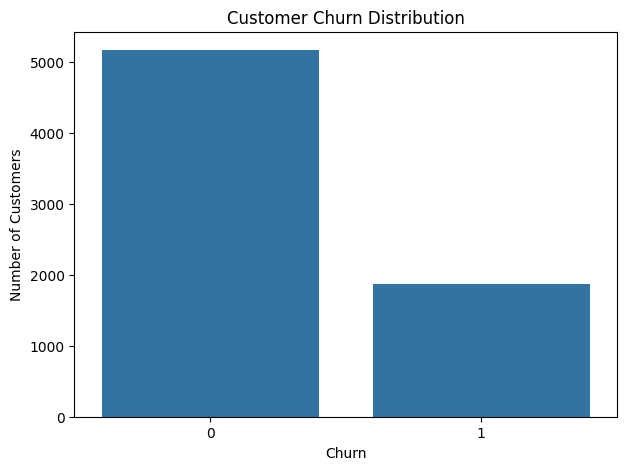

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=churn_df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

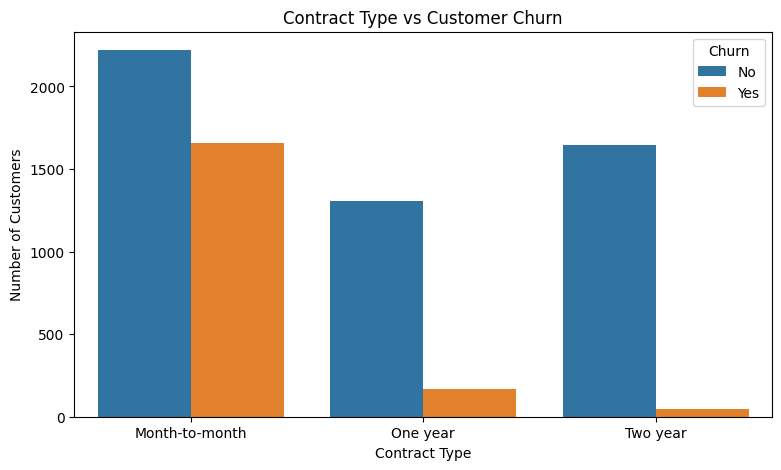

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

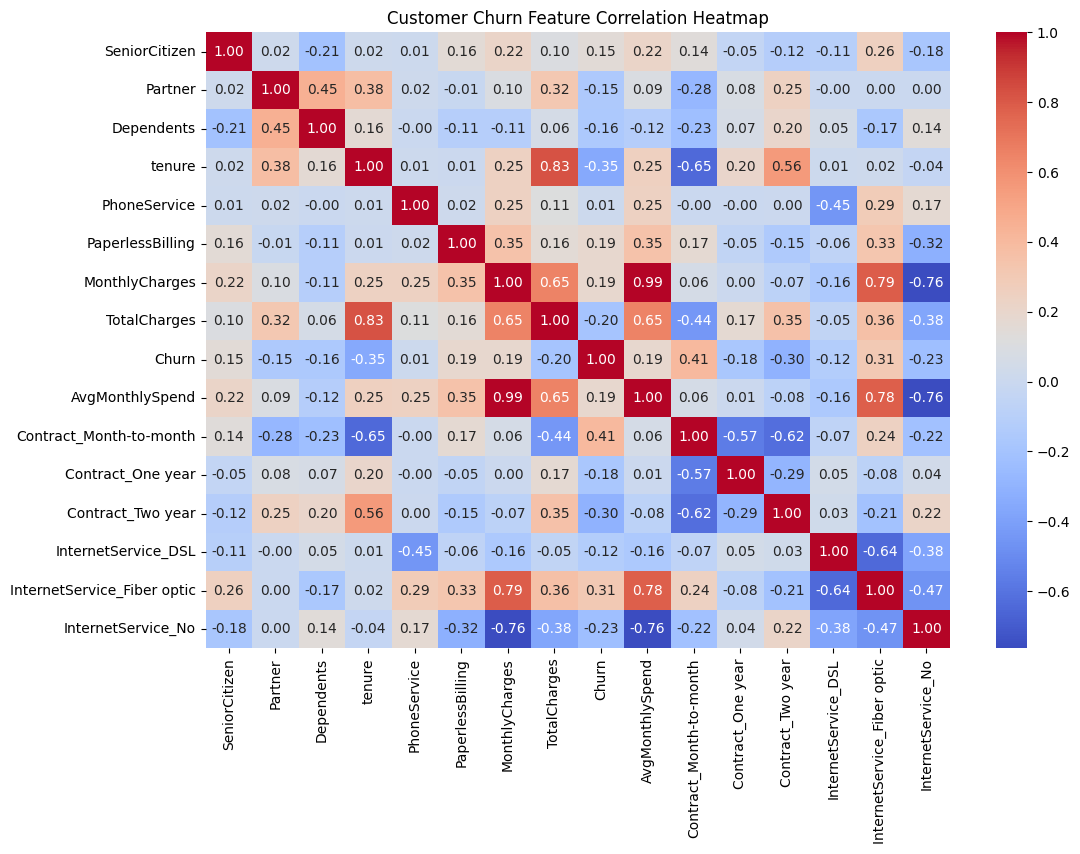

In [26]:
plt.figure(figsize=(12, 8))

correlation = churn_df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Churn Feature Correlation Heatmap")
plt.show()

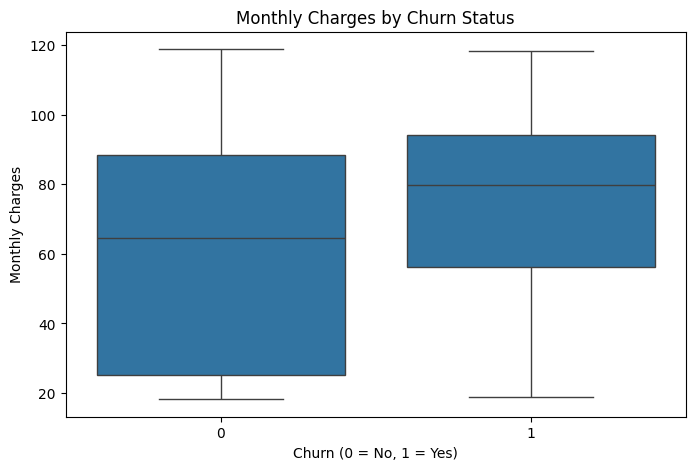

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=churn_df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")
plt.show()

In [28]:
# Calculate overall churn percentage
churn_percentage = churn_df["Churn"].value_counts(
    normalize=True
) * 100

print("Churn Percentage:")
print(churn_percentage.round(2))

# Calculate churn percentage by contract
contract_churn = (
    df.groupby("Contract")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

print("\nChurn Percentage by Contract:")
display(contract_churn.round(2))

# Calculate average monthly charges by churn status
monthly_charge_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
)

print("\nMonthly Charges by Churn:")
display(monthly_charge_summary.round(2))

Churn Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Churn Percentage by Contract:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



Monthly Charges by Churn:


,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65



## 5. Key Insights and Findings

Based on the exploratory data analysis, the following five insights were identified:

1. **Overall Customer Churn:** Approximately 26.54% of customers have churned, while 73.46% have remained with the company. This indicates that customer retention is an important area for improvement.

2. **Month-to-Month Contracts:** Customers with month-to-month contracts have a churn rate of 42.71%, considerably higher than customers with one-year and two-year contracts.

3. **Long-Term Contracts:** The churn rate is only 11.27% for one-year contracts and 2.83% for two-year contracts. Longer contract commitments are associated with lower customer churn.

4. **Monthly Charges:** Customers who churned have an average monthly charge of 74.44, compared with 61.27 for customers who stayed. Higher monthly charges may be associated with customer churn.

5. **Customer Tenure:** Tenure has a negative correlation of -0.35 with churn, indicating that customers with longer relationships with the company tend to have lower churn.

### Overall Interpretation

The analysis suggests that contract type, monthly charges, and customer tenure are important factors associated with customer churn. The company could focus on improving customer retention through suitable contract options, pricing strategies, and engagement with newer customers.


## 6. Exporting the Cleaned Dataset

The cleaned and feature-engineered dataset is exported as a CSV file for future analysis and modeling.

In [29]:
# Export cleaned dataset
churn_df.to_csv(
    "Cleaned_Customer_Churn.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Final Dataset Shape:", churn_df.shape)

Cleaned dataset exported successfully!
Final Dataset Shape: (7043, 27)


In [30]:
from google.colab import files

files.download("Cleaned_Customer_Churn.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>